# Project 3: Toxic Comment Detection on YouTube

## Notebook 2 of 3: Data Cleaning | EDA | Labelling | Preprocessing

**Contents**
1. Import and combine the raw data
2. Data cleaning
3. Exploratory data analysis
4. Labelling with Detoxify
5. Text preprocessing
6. Save data for modelling

In [1]:
# Import libraries
import glob
import os
import re
import time
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem.porter import PorterStemmer

from sklearn.feature_extraction.text import CountVectorizer

import torch
from detoxify import Detoxify

pd.options.display.max_colwidth = 200
sns.set_style('whitegrid')

In [2]:
# Download NLTK resources (skipped if already available)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

### 1. Import and combine the raw data

In [3]:
# Read the csv file of each video and combine into one dataframe
raw_files = sorted(glob.glob('../data/raw/comments_*.csv'))
data = pd.concat([pd.read_csv(f, low_memory=False) for f in raw_files], ignore_index=True)

In [4]:
# Data Summary
def data_summary(df):
    print(f'Shape(row,col): {df.shape}')
    print(f'Number of duplicates: {df.duplicated().sum()}')
    print('-'*60)
    print(f'Number of each unique datatypes:\n{df.dtypes.value_counts()}')
    print('-'*60)
    print('Columns containing missing values:')
    isnull_df = pd.DataFrame(df.isnull().sum()).reset_index()
    isnull_df.columns = ['col','num_nulls']
    isnull_df['null_pct'] = (isnull_df['num_nulls']/len(df)).round(2)
    df_nullcheck = isnull_df[isnull_df['num_nulls']>0]
    if len(df_nullcheck) == 0:
        print('None')
    else:
        print(df_nullcheck)

data_summary(data)

Shape(row,col): (40000, 14)
Number of duplicates: 0
------------------------------------------------------------
Number of each unique datatypes:
object    12
bool       1
int64      1
dtype: int64
------------------------------------------------------------
Columns containing missing values:
                 col  num_nulls  null_pct
1        textDisplay          7      0.00
2       textOriginal          7      0.00
3           parentId      26602      0.67
4  authorDisplayName          3      0.00
6   authorChannelUrl          3      0.00


In [5]:
data.head()

,videoId,textDisplay,textOriginal,parentId,authorDisplayName,authorProfileImageUrl,authorChannelUrl,authorChannelId,canRate,viewerRating,likeCount,publishedAt,updatedAt,comment_id
0,1GyRS20MUmU,*Watch our Collab on Hungry Fat Chick's channel:* https://www.youtube.com/watch?v=SfR4Jm8fbFA\n *Get this Hoodie for Christmas* 🎄🎁: https://ItsJustWaterWeight.com,*Watch our Collab on Hungry Fat Chick's channel:* https://www.youtube.com/watch?v=SfR4Jm8fbFA\n *Get this Hoodie for Christmas* 🎄🎁: https://ItsJustWaterWeight.com,NaN,@NikocadoAvocado,https://yt3.ggpht.com/ytc/AIdro_nBnjD4WeFcr_iq69boe-mICLtI7OIzEE2QDPaxjYbsMcU=s48-c-k-c0x00ffffff-no-rj,http://www.youtube.com/@NikocadoAvocado,{'value': 'UCDwzLWgGft47xQ30u-vjsrg'},True,none,3838,2021-12-06T22:46:32Z,2021-12-06T22:46:32Z,UgzATxH6J4vRo5QsaYp4AaABAg
1,1GyRS20MUmU,Diabetes.,Diabetes.,UgzATxH6J4vRo5QsaYp4AaABAg,@David-ve5iq,https://yt3.ggpht.com/XLK65n5fHC_yxTxnuxTf1ybmK8AXbTwtaqH-bUNf4BnE47qVYm_-lJpjFsjWsMYpF0JC8YK7DQ=s48-c-k-c0x00ffffff-no-rj,http://www.youtube.com/@David-ve5iq,{'value': 'UCxBLIiKHgsrGIduNcDxyjqA'},True,none,742,2021-12-06T22:46:52Z,2021-12-06T22:46:52Z,UgzATxH6J4vRo5QsaYp4AaABAg.9VcemEsd0e09VceocTGg-o
2,1GyRS20MUmU,Use me as dislike button,Use me as dislike button,UgzATxH6J4vRo5QsaYp4AaABAg,@alifhidayat8027,https://yt3.ggpht.com/ytc/AIdro_lN1r14JyVE1HV827fOA4jwcUpML9JATe2vub3wBZwgdO1_u1mEpcWHSejRd9oj5lcaaA=s48-c-k-c0x00ffffff-no-rj,http://www.youtube.com/@alifhidayat8027,{'value': 'UCUjOc0F7SVxd_Hx6cH-d4rw'},True,none,3448,2021-12-06T22:47:37Z,2021-12-06T22:47:37Z,UgzATxH6J4vRo5QsaYp4AaABAg.9VcemEsd0e09Vceu8m6gs0
3,1GyRS20MUmU,I was watching one of ur videos and I got ur notification for the video,I was watching one of ur videos and I got ur notification for the video,UgzATxH6J4vRo5QsaYp4AaABAg,@malyssaabasolo6680,https://yt3.ggpht.com/ytc/AIdro_mNJB6galzvTnYawShJKU9TASR7TQy7R165GPIfDGtgTw3ICE6qUNVw7Rqi7mRUqtio2A=s48-c-k-c0x00ffffff-no-rj,http://www.youtube.com/@malyssaabasolo6680,{'value': 'UCSprYoYRMEKbnjjXlHO3g4g'},True,none,135,2021-12-06T22:47:47Z,2021-12-06T22:47:47Z,UgzATxH6J4vRo5QsaYp4AaABAg.9VcemEsd0e09VcevM45G4T
4,1GyRS20MUmU,don’t care + didn’t ask + L + ratio + you fell off + no,don’t care + didn’t ask + L + ratio + you fell off + no,UgzATxH6J4vRo5QsaYp4AaABAg,@Capillum1337,https://yt3.ggpht.com/aGkw-dUuG6c5DVIeZ9nUCDKToBeMX4vedX_EyB2Ew6ylxl-iwTwrdbS4QcoSXyikYzPWm_EP_A=s48-c-k-c0x00ffffff-no-rj,http://www.youtube.com/@Capillum1337,{'value': 'UCbYOUxcnrygIKGjt-7w-oVA'},True,none,482,2021-12-06T22:49:34Z,2021-12-06T22:49:34Z,UgzATxH6J4vRo5QsaYp4AaABAg.9VcemEsd0e09Vcf7OvPyYe


**Dataset Dictionary**

| Name                  | Description                                                                                                                      |
| --------------------- | -------------------------------------------------------------------------------------------------------------------------------- |
| videoId               | The ID of the video the comment refers to.                                                                                       |
| textDisplay           | The comment's text as displayed, which may contain HTML or have links replaced by video titles.                                  |
| textOriginal          | The comment's original raw text as initially posted or last updated.                                                             |
| parentId              | The unique id of the parent comment, only set for replies.                                                                       |
| authorDisplayName     | The name of the user who posted the comment.                                                                                     |
| authorProfileImageUrl | The URL for the avatar of the user who posted the comment.                                                                       |
| authorChannelUrl      | Link to the author's YouTube channel, if any.                                                                                    |
| authorChannelId       | The id of the author's YouTube channel, if any.                                                                                  |
| canRate               | Whether the current viewer can rate this comment.                                                                                |
| viewerRating          | The rating the viewer has given to this comment.                                                                                 |
| likeCount             | The total number of likes this comment has received.                                                                             |
| publishedAt           | The date and time when the comment was orignally published (ISO 8601 format).                                                    |
| updatedAt             | The date and time when the comment was last updated (ISO 8601 format).                                                           |
| comment_id            | The unique id of the comment. The id of a reply has the form `<parent id>.<reply id>`.                                           |

### 2. Data cleaning

#### 2.1 Check that values are in the correct columns

Comments extracted with an earlier version of Notebook 1 (in April 2023) had, for most rows, the values after `textOriginal` written one column to the left, which left `updatedAt` empty. The current data was extracted with the corrected code, so this check confirms that the problem no longer occurs: a shifted row would have 'none' (a viewer rating) in the `canRate` column and no value in `updatedAt`.

In [6]:
# Compare rows with and without a value in updatedAt
cols = ['textOriginal', 'parentId', 'authorChannelId', 'canRate', 'viewerRating', 'likeCount', 'publishedAt', 'updatedAt']
display(data.loc[data['updatedAt'].notna(), cols].head(3))
display(data.loc[data['updatedAt'].isna(), cols].head(3))

,textOriginal,parentId,authorChannelId,canRate,viewerRating,likeCount,publishedAt,updatedAt
0,*Watch our Collab on Hungry Fat Chick's channel:* https://www.youtube.com/watch?v=SfR4Jm8fbFA\n *Get this Hoodie for Christmas* 🎄🎁: https://ItsJustWaterWeight.com,NaN,{'value': 'UCDwzLWgGft47xQ30u-vjsrg'},True,none,3838,2021-12-06T22:46:32Z,2021-12-06T22:46:32Z
1,Diabetes.,UgzATxH6J4vRo5QsaYp4AaABAg,{'value': 'UCxBLIiKHgsrGIduNcDxyjqA'},True,none,742,2021-12-06T22:46:52Z,2021-12-06T22:46:52Z
2,Use me as dislike button,UgzATxH6J4vRo5QsaYp4AaABAg,{'value': 'UCUjOc0F7SVxd_Hx6cH-d4rw'},True,none,3448,2021-12-06T22:47:37Z,2021-12-06T22:47:37Z


,textOriginal,parentId,authorChannelId,canRate,viewerRating,likeCount,publishedAt,updatedAt


In [7]:
# Rows where the values are shifted have 'none' (the viewer rating) in the canRate column
shifted = data['canRate'] == 'none'
print(f'Rows with shifted values: {shifted.sum()} ({shifted.mean():.1%})')
print(f"Of which updatedAt is missing: {data.loc[shifted, 'updatedAt'].isna().mean():.1%}")

Rows with shifted values: 0 (0.0%)
Of which updatedAt is missing: nan%


**Comments**

* No rows have shifted values (the table of shifted rows is empty), and `updatedAt` has no missing values, so every value is in its correct column. The share of shifted rows with a missing `updatedAt` is shown as `nan%` simply because there are no shifted rows to compute it on.
* The code below keeps the step that would recover shifted values, so that the notebook still works with data extracted by the earlier version.
* Whether a comment is a reply is taken from the comment id (the id of a reply contains the id of its parent, separated by a dot), which is reliable for all rows.
* The other columns (author details, `canRate`, `viewerRating`, `updatedAt`) are not needed for this project and are dropped. Dropping the author's name and channel also avoids keeping personal information that is not needed.

In [8]:
# Build a clean dataframe with only the columns needed, taking the values from the correct column for shifted rows
df = pd.DataFrame({
    'comment_id': data['comment_id'],
    'video_id': data['videoId'],
    'text': data['textOriginal'],
    # reply ids have the form <parent id>.<reply id>
    'is_reply': data['comment_id'].str.contains('.', regex=False).astype(int),
    'like_count': np.where(shifted, data['viewerRating'], data['likeCount']),
    'published_at': np.where(shifted, data['likeCount'], data['publishedAt'])
})

df['like_count'] = df['like_count'].astype(int)
df['published_at'] = pd.to_datetime(df['published_at'])

df.dtypes

comment_id                   object
video_id                     object
text                         object
is_reply                      int64
like_count                    int64
published_at    datetime64[ns, UTC]
dtype: object

#### 2.2 Missing values and duplicates

In [9]:
# Missing values
df.isnull().sum()

comment_id      0
video_id        0
text            7
is_reply        0
like_count      0
published_at    0
dtype: int64

In [10]:
# Drop comments with no text
df = df.dropna(subset=['text']).copy()

# Use the same line break character throughout (some comments contain carriage returns, which break the rows when saved to csv)
df['text'] = df['text'].str.replace(r'\r\n?', '\n', regex=True).str.strip()

# Check that each comment appears only once
print(f"Duplicated comment ids: {df['comment_id'].duplicated().sum()}")
df.shape

Duplicated comment ids: 0


(39993, 6)

In [11]:
# Comments with exactly the same text (ignoring case and extra spaces)
normalised = df['text'].str.lower().str.replace(r'\s+', ' ', regex=True)
print(f'Comments whose text duplicates an earlier comment: {normalised.duplicated().sum()}')
normalised[normalised.duplicated(keep=False)].value_counts().head(10)

Comments whose text duplicates an earlier comment: 3355


lol     146
me      137
fr      103
yes      76
lmao     75
no       74
fat      70
ikr      61
hi       54
true     51
Name: text, dtype: int64

**Comments**

* Only 7 comments have no text, and these are dropped.
* No comment id appears more than once, so no comment was extracted twice.
* However, 3,355 comments have the same text as an earlier comment. These are mostly very short reactions ('lol', 'fr', 'yes', 'lmao', 'ikr') and single words ('fat'). They are kept for the EDA and labelling, and handled in the preprocessing section after the text has been cleaned, where even more comments become identical to one another.

#### 2.3 Top-level comments and replies

In [12]:
# Number of top-level comments (0) and replies (1)
df['is_reply'].value_counts()

0    26597
1    13396
Name: is_reply, dtype: int64

In [13]:
# Check if the parent comments of the replies are in the data
parent_ids = df.loc[df['is_reply'] == 1, 'comment_id'].str.split('.').str[0].drop_duplicates()
top_level_ids = df.loc[df['is_reply'] == 0, 'comment_id']
print(f'Threads with replies: {len(parent_ids)}')
print(f'Of which the top-level comment is in the data: {parent_ids.isin(top_level_ids).sum()}')

# Maximum number of replies collected per thread
print(f"Maximum replies per thread: {df.loc[df['is_reply'] == 1, 'comment_id'].str.split('.').str[0].value_counts().max()}")

Threads with replies: 6943
Of which the top-level comment is in the data: 6943
Maximum replies per thread: 5


**Comments**

* 26,597 comments (67%) are top-level comments and 13,396 (33%) are replies.
* The replies belong to 6,943 threads, and the top-level comment of every one of these threads is in the data, so the conversations are complete.
* At most 5 replies are collected per thread, which is the number of replies the API returns together with a thread. Threads with more than 5 replies are therefore only partly collected.

### 3. Exploratory data analysis

#### 3.1 Comments per video and over time

In [14]:
# Short names of the videos for plotting
video_names = {
    'd3JkqJycmAg': 'We Broke Up (Mar 2021)',
    'd-tOb3SDeRw': 'House Tour (Apr 2021)',
    '1GyRS20MUmU': 'Blue Takis Mukbang (Dec 2021)',
    'lrVIDuKvyMw': 'Fire Noodle Mukbang (Feb 2023)'
}
df['video'] = df['video_id'].map(video_names)

video_summary = df.groupby('video').agg(comments=('comment_id', 'count'),
                                        reply_share=('is_reply', 'mean'),
                                        median_likes=('like_count', 'median'),
                                        first_comment=('published_at', 'min'),
                                        last_comment=('published_at', 'max'))
video_summary.loc[list(video_names.values())].round(2)

,comments,reply_share,median_likes,first_comment,last_comment
video,,,,,
We Broke Up (Mar 2021),10000,0.38,1.0,2021-03-06 19:00:48+00:00,2026-10-10 21:54:38+00:00
House Tour (Apr 2021),10000,0.41,2.0,2021-04-01 19:01:29+00:00,2026-09-03 12:36:36+00:00
Blue Takis Mukbang (Dec 2021),9996,0.27,1.0,2021-12-06 22:46:32+00:00,2026-10-13 14:26:45+00:00
Fire Noodle Mukbang (Feb 2023),9997,0.28,1.0,2023-02-16 21:02:21+00:00,2026-09-19 20:54:44+00:00


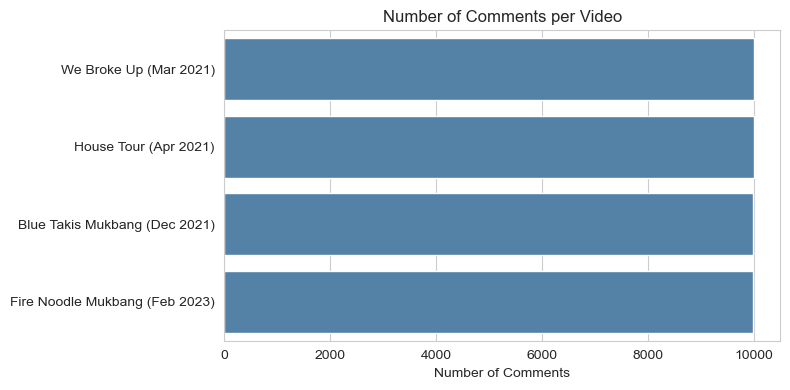

In [15]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='video', order=list(video_names.values()), color='steelblue')
plt.title('Number of Comments per Video')
plt.xlabel('Number of Comments')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../images/comments_per_video.png', dpi=120)
plt.show()

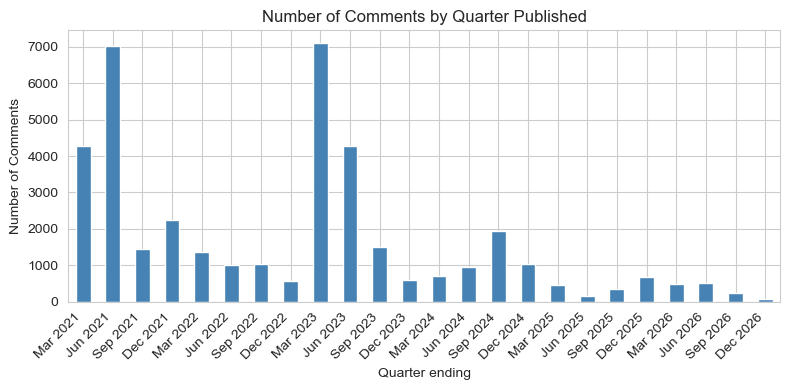

In [16]:
# Number of comments published per quarter
quarterly = df.set_index('published_at').resample('Q')['comment_id'].count()
quarterly.index = quarterly.index.strftime('%b %Y')

plt.figure(figsize=(8, 4))
quarterly.plot(kind='bar', color='steelblue')
plt.title('Number of Comments by Quarter Published')
plt.xlabel('Quarter ending')
plt.ylabel('Number of Comments')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comments**

* Each video has about 10,000 comments (between 9,996 and 10,000 after dropping comments with no text), as a limit of 10,000 comments per video was set in Notebook 1. No single video dominates the data, and the model's performance is also checked for each video separately in Notebook 3.
* The share of replies differs between videos, from 27% for the two mukbang videos to 41% for the house tour. The median comment has 1 or 2 likes.
* The API returns comments newest first, so the period covered differs by video:
    * For *We Broke Up* and *House Tour*, the 10,000 most recent comments go back to the day each video was released, so most of their comments are from 2021.
    * For the *Blue Takis Mukbang*, they only go back to February 2023, more than a year after it was released. (The one comment from December 2021 is the creator's pinned comment, which the API returns first.)
    * For the *Fire Noodle Mukbang*, they go back to about a week after it was released.
* This explains the two peaks in the chart by quarter: April to June 2021 (after the release of the first two videos) and January to March 2023 (the release of the Fire Noodle video). All four videos were still receiving comments in 2026, up to the extraction on 14 October 2026.

#### 3.2 Length of comments and outliers

In [17]:
# Number of characters and words in each comment
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

df[['char_count', 'word_count', 'like_count']].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(1)

,char_count,word_count,like_count
count,39993.0,39993.0,39993.0
mean,50.9,9.8,6.2
std,85.0,14.5,123.2
min,1.0,1.0,0.0
25%,17.0,3.0,0.0
50%,33.0,6.0,1.0
75%,62.0,12.0,4.0
99%,301.0,57.0,34.0
max,6690.0,1009.0,14766.0


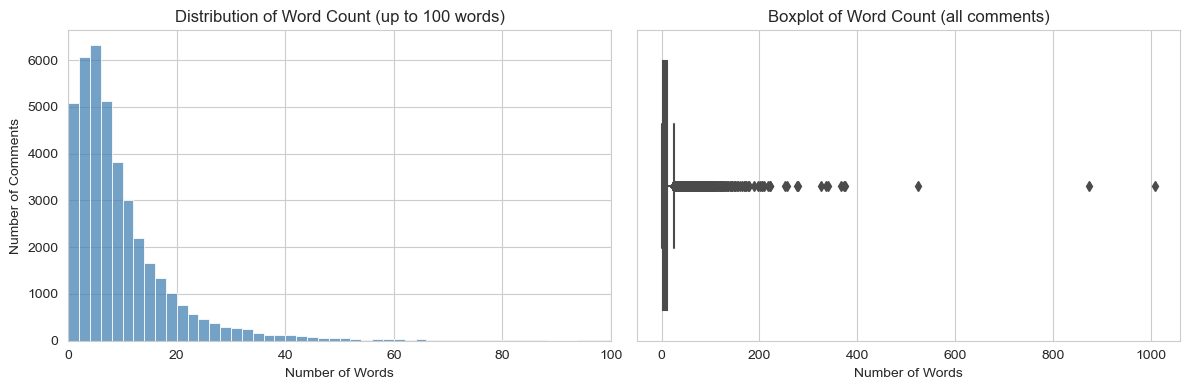

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['word_count'], bins=range(0, 101, 2), ax=ax[0], color='steelblue')
ax[0].set_xlim(0, 100)
ax[0].set_title('Distribution of Word Count (up to 100 words)')
ax[0].set_xlabel('Number of Words')
ax[0].set_ylabel('Number of Comments')

sns.boxplot(x=df['word_count'], ax=ax[1], color='steelblue')
ax[1].set_title('Boxplot of Word Count (all comments)')
ax[1].set_xlabel('Number of Words')

plt.tight_layout()
plt.savefig('../images/word_count.png', dpi=120)
plt.show()

In [19]:
# Look at the longest comments
print(f"Comments with more than 200 words: {(df['word_count'] > 200).sum()}")

longest = df.sort_values('word_count', ascending=False).head(8)[['text', 'word_count']].copy()
longest['unique_words'] = longest['text'].str.lower().str.split().apply(lambda words: len(set(words)))
longest['text'] = longest['text'].str[:120]
longest

Comments with more than 200 words: 20


,text,word_count,unique_words
28850,i think it means a serious disagreement or argument typically a protracted onei think it means a serious disagreement or,1009,13
11569,His Balcony = Super duper super duperSuper duper super duperSuper duper super duperSuper duper super duperSuper duper s,873,9
36700,Stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop stop,523,3
11455,"How can anybody get to Heaven?✨\n\nYou might think that all you have to do is be a good person, go to church every sunday,",374,203
28853,i think it means a serious disagreement or argument typically a protracted onei think it means a serious disagreement or,373,13
22853,"I’m not trying to offend you in any way but you said you didn’t know why you were so overweight, right? Well that’s beca",367,182
32327,"Drinking enough water is essential for good health, but did you know that it can also help you lose weight? It's true: i",341,168
22094,Sweetheart you have to start taking accountability for the role you had to play in ur weight gain. This is not water wei,335,174


In [20]:
# Share of very long comments that are repetitive (fewer than half of the words are unique)
long_comments = df[df['word_count'] > 200]
unique_ratio = long_comments['text'].str.lower().str.split().apply(lambda words: len(set(words)) / len(words))
print(f'Share of comments > 200 words where fewer than half of the words are unique: {(unique_ratio < 0.5).mean():.0%}')

Share of comments > 200 words where fewer than half of the words are unique: 50%


**Comments**

* Comments are short: half of them have 6 words or fewer, 75% have 12 words or fewer and 99% have 57 words or fewer. The distribution is heavily skewed to the right.
* Likes are even more skewed: the median comment has 1 like and 99% have 34 or fewer, while the most liked comment has 14,766.
* There are 20 comments with more than 200 words, up to 1,009 words. These are the outliers in the boxplot. Half of them are made up of the same few words repeated many times (e.g. 'Super duper' or 'Stop' pasted over and over), i.e. spam, and the others are mostly long lectures or copied texts (e.g. about health or religion) rather than reactions to the video.
* These 20 comments (0.05% of the data) are dropped. Their repeated words would be counted hundreds of times by the vectorizers, and they are longer than what the labelling model reads in full (it reads up to 512 tokens).

In [21]:
# Drop comments with more than 200 words
df = df[df['word_count'] <= 200].copy()
df.shape

(39973, 9)

### 4. Labelling with Detoxify

The comments do not come with a label of whether they are toxic. They are labeled using [Detoxify](https://github.com/unitaryai/detoxify), an open-source pre-trained model, which replaces Google's Perspective API as the latter will be shut down on 31 December 2026.

* Detoxify's `original` model is a BERT model fine-tuned on about 160,000 Wikipedia comments which were **labeled by human raters** for the [Jigsaw Toxic Comment Classification Challenge](https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge). It defines a toxic comment as a rude, disrespectful or unreasonable comment that is likely to make someone leave a discussion.
* For each comment, it returns a toxicity score between 0 and 1.
* It runs locally with no API key, request limit or cost, so **all** comments can be labeled and the labels can be reproduced by anyone.
* The **original text** of the comment is passed to the model (not the cleaned text), since the model was trained on natural text and makes use of casing, punctuation and word order.

In [22]:
def score_toxicity(texts, batch_size=64):
    """Return the Detoxify toxicity score (0 to 1) of each text."""
    # Use the GPU if there is one
    if torch.backends.mps.is_available():
        device = 'mps'
    elif torch.cuda.is_available():
        device = 'cuda'
    else:
        device = 'cpu'
    model = Detoxify('original', device=device)

    # Score comments of similar length together, so that less padding is needed in each batch
    order = np.argsort([len(text) for text in texts])
    scores = np.zeros(len(texts))
    for start in range(0, len(texts), batch_size):
        batch = order[start:start + batch_size]
        scores[batch] = model.predict([texts[i] for i in batch])['toxicity']
    return scores

In [23]:
# Scoring all comments takes several minutes, so the scores are saved and re-used if the notebook is re-run
scores_file = '../data/detoxify_scores.csv'

if os.path.isfile(scores_file):
    scores = pd.read_csv(scores_file)
    print(f'Loaded {len(scores)} saved scores')
else:
    start_time = time.time()
    scores = pd.DataFrame({'comment_id': df['comment_id'].values,
                           'toxicity': score_toxicity(df['text'].tolist())})
    scores.to_csv(scores_file, index=False)
    print(f'Scored {len(scores)} comments in {(time.time() - start_time) / 60:.1f} minutes')

df = df.merge(scores, on='comment_id', how='left', validate='one_to_one')

# Check that every comment has a score
df['toxicity'].isnull().sum()

Loaded 39973 saved scores


0

In [24]:
df['toxicity'].describe().round(3)

count    39973.000
mean         0.187
std          0.309
min          0.001
25%          0.002
50%          0.014
75%          0.212
max          0.999
Name: toxicity, dtype: float64

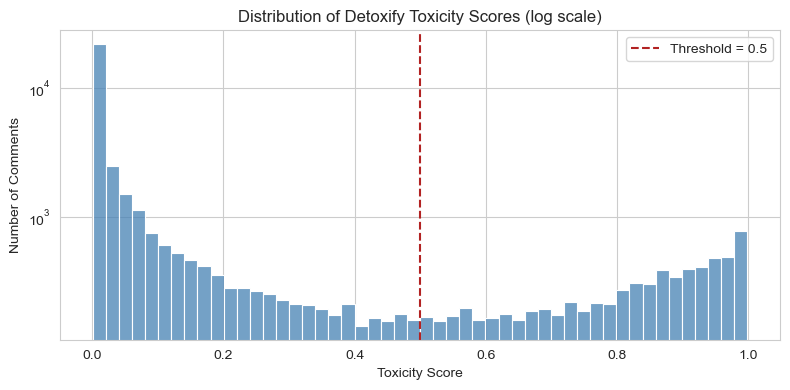

In [25]:
# Distribution of toxicity scores
plt.figure(figsize=(8, 4))
sns.histplot(df['toxicity'], bins=50, color='steelblue')
plt.axvline(0.5, color='firebrick', linestyle='--', label='Threshold = 0.5')
plt.yscale('log')
plt.title('Distribution of Detoxify Toxicity Scores (log scale)')
plt.xlabel('Toxicity Score')
plt.ylabel('Number of Comments')
plt.legend()
plt.tight_layout()
plt.savefig('../images/toxicity_scores.png', dpi=120)
plt.show()

In [26]:
# Share of comments in each range of toxicity score
bands = pd.cut(df['toxicity'], bins=[0, 0.1, 0.3, 0.5, 0.7, 0.9, 1], include_lowest=True)
bands.value_counts(normalize=True).sort_index().round(3)

(-0.001, 0.1]    0.685
(0.1, 0.3]       0.093
(0.3, 0.5]       0.046
(0.5, 0.7]       0.044
(0.7, 0.9]       0.067
(0.9, 1.0]       0.064
Name: toxicity, dtype: float64

In [27]:
# Sample of comments in each range of toxicity score, to check if the scores are sensible
pd.concat([group.sample(4, random_state=42) for _, group in df.groupby(bands)])[['text', 'toxicity']].round(2)

,text,toxicity
17393,wiet.,0.00
28505,@Crosby Kuzel 🤣,0.00
1460,The way he said I’m so skinny today even ask,0.01
8001,E,0.00
13010,OMG denial of truth right on its face....dude take care of your self....its not too l8 for anything,0.11
6468,cry,0.22
4309,that's crazy,0.24
12525,"That applies to you, lacking braincells as if he just magically gained all the weight for ""playing a character"". You're such an enabler! You certainly supports toxic positivity.",0.27
15487,God I wish I had your Hair line,0.32
9045,"@Vincemm2 listen, idk if you like him or hate him but “emogies”??",0.36


**Comments**

* When this notebook was first run, scoring all 39,973 comments took 2.7 minutes on a laptop GPU, with no errors or missing scores. The scores were saved, so the output above shows them being loaded from the file instead of scored again.
* The scores are concentrated at the two ends: about 69% of comments score below 0.1 and about 13% score above 0.7. Only about 9% of comments fall in the uncertain range between 0.3 and 0.7.
* From the sample, the scores are generally sensible. Neutral comments score close to 0 ('The way he said I'm so skinny today...' scores 0.01), and insults score close to 1 ('Why do these two morons still exist?!' scores 0.90, 'Wow no one knows why your fat' scores 0.88).
* Some limitations can also be seen:
    * Comments that express concern in blunt terms also get high scores ('Nick it's because eating junk all day eat healthier ur killing yourself' scores 0.96).
    * So do comments that call out other viewers for being toxic ('That's an actual human being your talking about. Be respectful of the dead...' scores 0.98) or defend the creator in capital letters ('GUYS! STOP HATING! HE IS NOW SKINNY AND KIND!!!!!' scores 0.88).
    * Profanities that are not aimed at anyone also score high ('Wtf am I watching I'm only 2 mins in💀' scores 0.82).
    * The model is trained on English comments, so comments in other languages tend to get low scores regardless of what they say.
* A comment is labeled as toxic if its score is **0.5 or above**. Detoxify is trained as a classifier and its score is the probability that the comment is toxic, so 0.5 is its natural decision point. As few comments have scores close to 0.5, the labels are not very sensitive to the exact threshold chosen.

In [28]:
# Label comments with toxicity score of 0.5 and above as toxic (1), otherwise not toxic (0)
df['is_toxic'] = (df['toxicity'] >= 0.5).astype(int)

df['is_toxic'].value_counts(normalize=True).round(3)

0    0.825
1    0.175
Name: is_toxic, dtype: float64

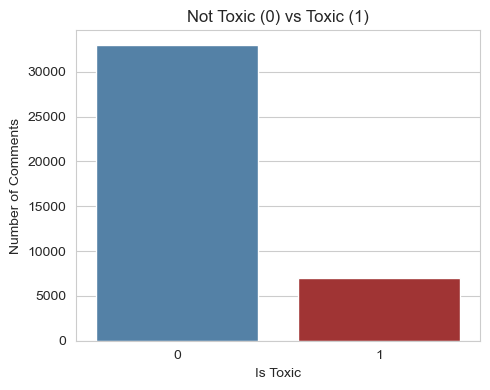

In [29]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='is_toxic', palette=['steelblue', 'firebrick'])
plt.title('Not Toxic (0) vs Toxic (1)')
plt.xlabel('Is Toxic')
plt.ylabel('Number of Comments')
plt.tight_layout()
plt.savefig('../images/class_balance.png', dpi=120)
plt.show()

#### 4.1 Toxic comments by video, type and length

In [30]:
# Share of toxic comments by video
df.groupby('video')['is_toxic'].agg(['mean', 'count']).loc[list(video_names.values())].round(3)

,mean,count
video,,
We Broke Up (Mar 2021),0.174,9991
House Tour (Apr 2021),0.186,9996
Blue Takis Mukbang (Dec 2021),0.136,9995
Fire Noodle Mukbang (Feb 2023),0.204,9991


In [31]:
# Share of toxic comments for top-level comments (0) and replies (1)
df.groupby('is_reply')['is_toxic'].agg(['mean', 'count']).round(3)

,mean,count
is_reply,,
0,0.191,26579
1,0.145,13394


In [32]:
# Length and likes of toxic and non-toxic comments
df.groupby('is_toxic')[['word_count', 'char_count', 'like_count']].agg(['mean', 'median']).round(1)

word_count        char_count        like_count       
               mean median       mean median       mean median
is_toxic                                                      
0               8.9    6.0       46.2   31.0        6.4    1.0
1              13.1    9.0       67.2   45.0        5.4    2.0

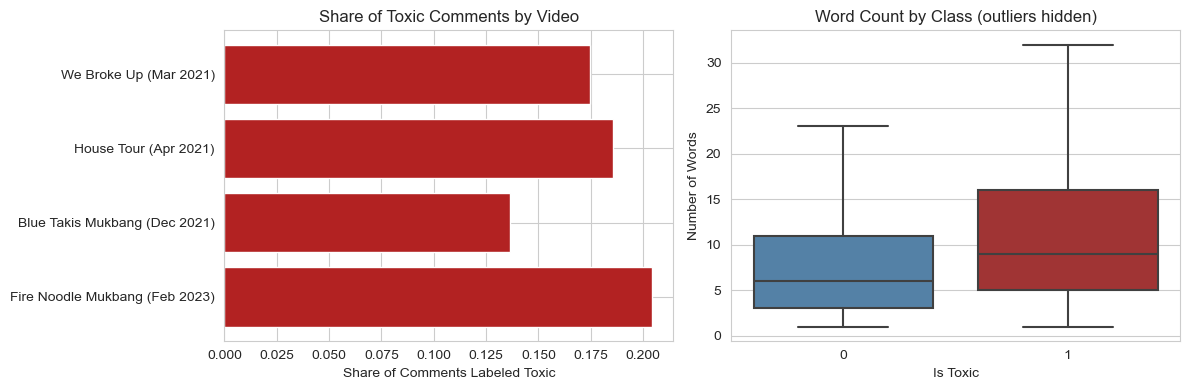

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

toxic_by_video = df.groupby('video')['is_toxic'].mean().loc[list(video_names.values())]
ax[0].barh(toxic_by_video.index, toxic_by_video.values, color='firebrick')
ax[0].invert_yaxis()
ax[0].set_title('Share of Toxic Comments by Video')
ax[0].set_xlabel('Share of Comments Labeled Toxic')

sns.boxplot(data=df, x='is_toxic', y='word_count', showfliers=False, palette=['steelblue', 'firebrick'], ax=ax[1])
ax[1].set_title('Word Count by Class (outliers hidden)')
ax[1].set_xlabel('Is Toxic')
ax[1].set_ylabel('Number of Words')

plt.tight_layout()
plt.savefig('../images/toxic_by_video.png', dpi=120)
plt.show()

**Comments**

* 17.5% of the comments are labeled toxic. The classes are imbalanced, so accuracy alone will not be a suitable metric for modelling.
* The share of toxic comments ranges from 13.6% for the Blue Takis mukbang to 20.4% for the Fire Noodle mukbang. The difference is moderate, and toxic comments are present in every video, so the data from the four videos can be combined for modelling.
* Top-level comments are more often toxic (19.1%) than replies (14.5%). A possible reason is that top-level comments are addressed to the creator, while replies are conversations among viewers.
* Toxic comments tend to be longer (median of 9 words compared to 6) and receive slightly more likes (median of 2 compared to 1), although the distributions overlap considerably. Length and likes on their own would not be enough to separate the classes, and likes are not available at the time a comment is posted, so the model will use the text only.

### 5. Text preprocessing

The text is prepared for modelling in steps, and the result of each step is kept in its own column so that the effect of each step can be compared in Notebook 3:

| Column | Processing |
| --- | --- |
| `clean_text` | Lowercase; remove URLs, mentions, emojis, numbers, punctuation and other non-letter characters; shorten letters repeated 3 or more times (e.g. 'waaaaay' to 'waay') |
| `text_stop` | `clean_text` with stop words removed |
| `text_stem` | `text_stop` with each word stemmed (Porter stemmer) |
| `text_lemma` | `text_stop` with each word lemmatized (WordNet lemmatizer) |

In [34]:
def clean_text(text):
    """Lowercase the text and keep only letters."""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # remove URLs
    text = re.sub(r'@\w+', ' ', text)                # remove mentions
    text = re.sub(r"['’]", '', text)                 # remove apostrophes, so that "don't" becomes "dont"
    text = re.sub(r'[^a-z\s]', ' ', text)            # remove emojis, numbers, punctuation and non-latin characters
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)       # shorten letters repeated 3 or more times
    return re.sub(r'\s+', ' ', text).strip()         # remove extra spaces


df['clean_text'] = df['text'].apply(clean_text)
df[['text', 'clean_text']].sample(5, random_state=1)

,text,clean_text
21146,i don’t think any girl would date him?,i dont think any girl would date him
19585,Chaves. Besos de Brasil.,chaves besos de brasil
21557,Why u broke up,why u broke up
13660,@farhiyoroone1237 watch this at 2x speed\nYou'll know what I mean,watch this at x speed youll know what i mean
35839,@eliz.k u could say he is giving his life for the role,k u could say he is giving his life for the role


In [35]:
# Comments with nothing left after cleaning, i.e. comments with only emojis, numbers or non-latin characters
empty = df['clean_text'] == ''
print(f'Comments with no text left after cleaning: {empty.sum()}')
df.loc[empty, 'text'].sample(8, random_state=42).tolist()

Comments with no text left after cleaning: 2351


['👌🏻', '💀💀', '🤮', '다이어트 자극 최고', '😂😂😂😂سمين', '😡', '29:13', '𝔗𝔞𝔨𝔦𝔰']

In [36]:
# Comments whose cleaned text is the same as an earlier comment
print(f"Comments whose cleaned text duplicates an earlier comment: {df.loc[~empty, 'clean_text'].duplicated().sum()}")

# Check if duplicates of the same cleaned text were given different labels
labels_per_text = df[~empty].groupby('clean_text')['is_toxic'].nunique()
print(f'Cleaned texts given both labels: {(labels_per_text > 1).sum()}')

Comments whose cleaned text duplicates an earlier comment: 4839
Cleaned texts given both labels: 44


**Comments**

* 2,351 comments have no text left after cleaning. These consist of only emojis, punctuation, timestamps, non-latin scripts (e.g. Korean, Arabic) or stylised Unicode letters. A model based on English words has nothing to work with for these, so they are dropped. This is a limitation: emojis can carry meaning, and toxic comments in other scripts will not be detected.
* A further 4,839 comments have the same cleaned text as an earlier comment (e.g. 'lol', 'LOL!!' and 'lol 😂' all become 'lol'). Only the first comment of each cleaned text is kept. If duplicates were kept, the same text could appear in both the train and test sets and make the test scores look better than they are.
* For 44 cleaned texts, the duplicates were given different labels. This is because Detoxify scored the original text, where casing, punctuation and emojis differ. These are few, and the label of the first comment is used.
* After these steps, 32,783 comments remain, of which 19.4% are toxic. The share of toxic comments is higher than before (17.5%) because the duplicated and emoji-only comments are mostly short, harmless reactions.

In [37]:
# Drop comments with no text left after cleaning
df = df[~empty].copy()
print(f'Comments after dropping those with no text left: {len(df)}')

# Keep the first comment of each cleaned text
df = df.drop_duplicates(subset='clean_text', keep='first').copy()
print(f'Comments after keeping one comment per cleaned text: {len(df)}')
print(f"Toxic comments: {df['is_toxic'].sum()} ({df['is_toxic'].mean():.1%})")

Comments after dropping those with no text left: 37622
Comments after keeping one comment per cleaned text: 32783
Toxic comments: 6355 (19.4%)


In [38]:
# Stop words, with apostrophes removed to match the cleaned text
stop_words = set(word.replace("'", '') for word in stopwords.words('english'))

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Words are repeated many times across comments, so results are cached for speed
@lru_cache(maxsize=None)
def stem(word):
    return stemmer.stem(word)

@lru_cache(maxsize=None)
def lemmatize(word):
    return lemmatizer.lemmatize(word)


def remove_stop_words(text):
    return ' '.join(word for word in text.split() if word not in stop_words)

def stem_text(text):
    return ' '.join(stem(word) for word in text.split())

def lemmatize_text(text):
    return ' '.join(lemmatize(word) for word in text.split())


df['text_stop'] = df['clean_text'].apply(remove_stop_words)
df['text_stem'] = df['text_stop'].apply(stem_text)
df['text_lemma'] = df['text_stop'].apply(lemmatize_text)

df[['text', 'clean_text', 'text_stop', 'text_stem', 'text_lemma']].sample(5, random_state=7)

,text,clean_text,text_stop,text_stem,text_lemma
21027,YOU WANT YOUR SEATBELT TO FIT HUH? THEN STOP EATING SO DAMN MUCH,you want your seatbelt to fit huh then stop eating so damn much,want seatbelt fit huh stop eating damn much,want seatbelt fit huh stop eat damn much,want seatbelt fit huh stop eating damn much
38880,I think I just got a brain tumor from watching this,i think i just got a brain tumor from watching this,think got brain tumor watching,think got brain tumor watch,think got brain tumor watching
5487,Little snack? This is portion for 100 people for one week i think,little snack this is portion for people for one week i think,little snack portion people one week think,littl snack portion peopl one week think,little snack portion people one week think
23045,he tries too hard to be funny and it doesn’t work😐💀,he tries too hard to be funny and it doesnt work,tries hard funny work,tri hard funni work,try hard funny work
14563,There is more dislike then like comments,there is more dislike then like comments,dislike like comments,dislik like comment,dislike like comment


In [39]:
# Number of unique words after each step
for col in ['clean_text', 'text_stop', 'text_stem', 'text_lemma']:
    vocabulary = set(word for text in df[col] for word in text.split())
    print(f'{col}: {len(vocabulary)} unique words')

# Comments made up of stop words only
print(f"Comments with only stop words: {(df['text_stop'] == '').sum()}")

clean_text: 16790 unique words
text_stop: 16613 unique words
text_stem: 13192 unique words
text_lemma: 15464 unique words
Comments with only stop words: 278


**Comments**

* Removing stop words barely changes the size of the vocabulary (16,790 to 16,613 unique words), but it removes many of the words in each comment, including words such as 'you' and 'your' which could be useful for telling if a comment is aimed at someone.
* Stemming reduces the vocabulary the most (to 13,192 words) by cutting words to their stems (e.g. 'tries' to 'tri', 'funny' to 'funni'), while lemmatization is more conservative (15,464 words) and returns proper words (e.g. 'tries' to 'try').
* 278 comments consist of stop words only, e.g. 'you are not'. They are kept as they still have text in `clean_text`.
* Which version works best will be determined by comparing the cross-validated scores of models trained on each version in Notebook 3.

#### 5.1 Most used words

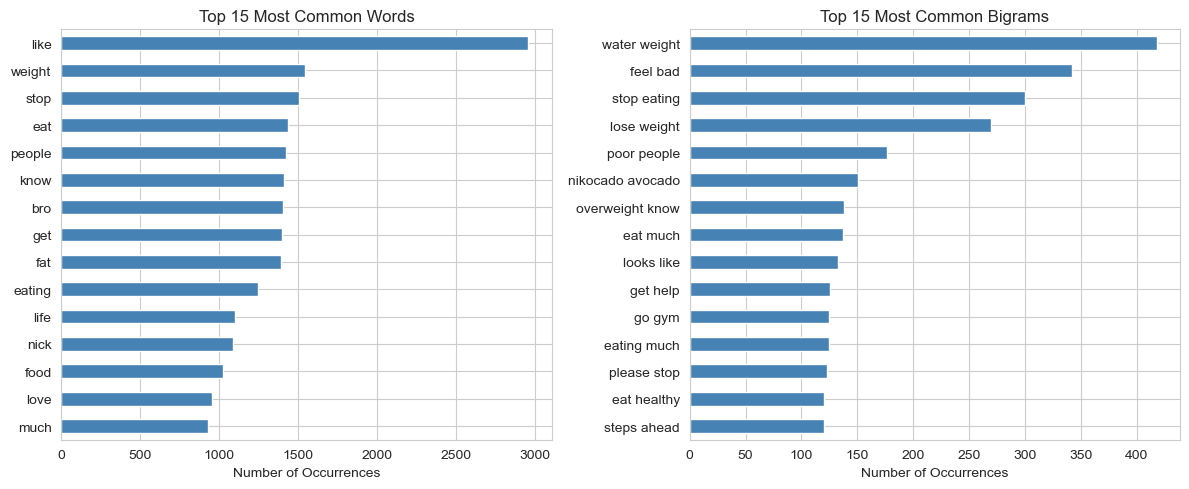

In [40]:
def top_words(texts, ngram_range=(1, 1), n=15):
    """Return the n most frequent words (or n-grams) in the texts."""
    cvec = CountVectorizer(ngram_range=ngram_range)
    counts = cvec.fit_transform(texts)
    totals = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cvec.get_feature_names_out())
    return totals.sort_values(ascending=False).head(n)


fig, ax = plt.subplots(1, 2, figsize=(12, 5))

top_words(df['text_stop']).sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title('Top 15 Most Common Words')
ax[0].set_xlabel('Number of Occurrences')

top_words(df['text_stop'], ngram_range=(2, 2)).sort_values().plot(kind='barh', ax=ax[1], color='steelblue')
ax[1].set_title('Top 15 Most Common Bigrams')
ax[1].set_xlabel('Number of Occurrences')

plt.tight_layout()
plt.savefig('../images/top_words.png', dpi=120)
plt.show()

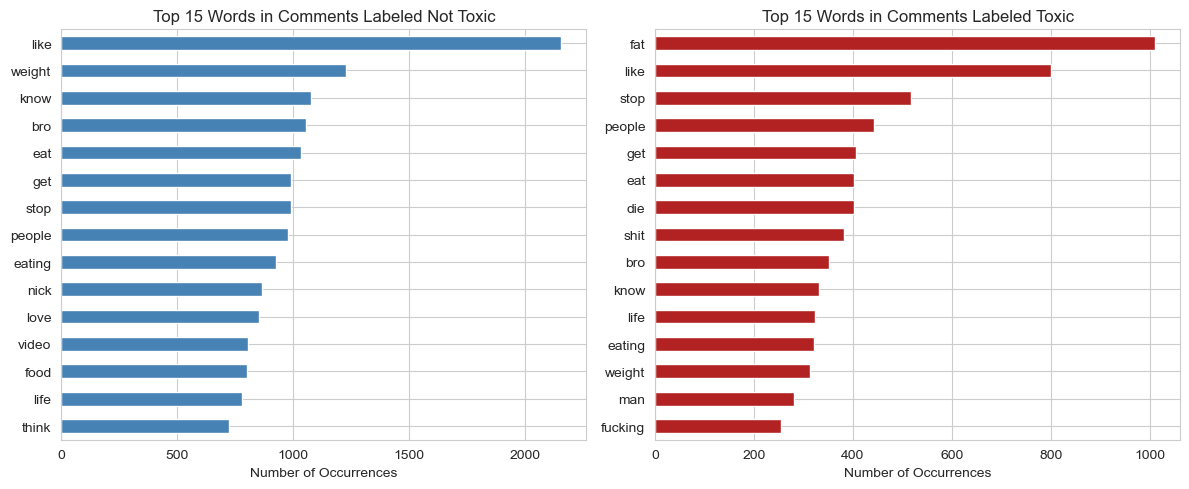

In [41]:
# Most common words in toxic and non-toxic comments
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

top_words(df.loc[df['is_toxic'] == 0, 'text_stop']).sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title('Top 15 Words in Comments Labeled Not Toxic')
ax[0].set_xlabel('Number of Occurrences')

top_words(df.loc[df['is_toxic'] == 1, 'text_stop']).sort_values().plot(kind='barh', ax=ax[1], color='firebrick')
ax[1].set_title('Top 15 Words in Comments Labeled Toxic')
ax[1].set_xlabel('Number of Occurrences')

plt.tight_layout()
plt.savefig('../images/top_words_by_class.png', dpi=120)
plt.show()

**Comments**

* The most common words and bigrams are about eating, weight and health ('stop eating', 'lose weight', 'eat healthy', 'go gym'), and appeals to the creator ('please stop', 'get help'). The most common bigram, 'water weight', is the creator's own catchphrase, which he also sells on merchandise (see the link in his pinned comment), and viewers repeat it.
* Many of the top words appear in both classes ('like', 'stop', 'eat', 'people', 'weight'), as they reflect the topic rather than the tone of a comment.
* The words that are distinctive of the toxic class are 'fat' (the most common word in toxic comments), 'die' and profanities, while 'love', 'video' and 'think' only appear among the top words of the non-toxic class.
* This suggests that the two classes can be separated by the words used, although the model will need to rely on a relatively small set of distinctive words rather than the topic words.

### 6. Save data for modelling

In [42]:
# Keep the columns needed for modelling
columns = ['comment_id', 'video_id', 'is_reply', 'like_count', 'published_at', 'word_count',
           'text', 'clean_text', 'text_stop', 'text_stem', 'text_lemma', 'toxicity', 'is_toxic']

df[columns].to_csv('../data/comments_labelled.csv', index=False)
df[columns].shape

(32783, 13)

#### 6.1 Sample for manual labelling

The labels come from a model, not from people. To check how well they agree with human judgement, a sample of 300 comments is saved for manual labelling, with 50 comments drawn from each range of toxicity score so that borderline comments are well represented. The toxicity score is left out of the file so that it does not influence the person labelling.

In [43]:
gold_file = '../data/gold_sample.csv'

if os.path.isfile(gold_file):
    print('Sample file already exists, not overwritten')
else:
    bands = pd.cut(df['toxicity'], bins=[0, 0.1, 0.3, 0.5, 0.7, 0.9, 1], include_lowest=True)
    gold = pd.concat([group.sample(50, random_state=42) for _, group in df.groupby(bands)])
    gold = gold.sample(frac=1, random_state=42)[['comment_id', 'text']]   # shuffle
    gold['human_is_toxic'] = np.nan
    gold.to_csv(gold_file, index=False)
    print(f'Saved {len(gold)} comments for manual labelling')

Sample file already exists, not overwritten


### Summary

| Step | Comments remaining |
| --- | --- |
| Raw data from four videos | 40,000 |
| Drop comments with no text | 39,993 |
| Drop comments with more than 200 words | 39,973 |
| Drop comments with no text left after cleaning | 37,622 |
| Keep one comment per cleaned text | 32,783 |

**Can the problem statement be answered with this data?**

* **Quantity:** There are 32,783 unique comments for modelling, of which 6,355 (19.4%) are toxic. This is sufficient to train and evaluate classification models, including on the minority class.
* **Signal:** The EDA shows that toxic and non-toxic comments differ in the words used, which is what a model based on word counts needs.
* **Caveats:**
    * The labels are produced by a model (Detoxify) and not by people, so the models in Notebook 3 learn to reproduce Detoxify's judgement. A sample has been set aside for manual labelling to check this.
    * All comments are from one creator's videos, so the vocabulary is specific to this community (food, weight, health).
    * The comments are the 10,000 most recent of each video, so for the Blue Takis mukbang the comments from the first year after its release are not included.